# Week 4 Lab: Roadside Smart-Camera, Part 2: Fine-Tuning With Only 5,000 Labelled Photos
**Course:** Image and Scene Recognition, Kyungdong University Global
**Name:** _your name_  |  **Student ID:** _your ID_

## AI assistance disclosure
An AI coding assistant (Claude, by Anthropic) was used for this notebook: it assembled the code cells from the lab tutorial, ran the notebook on a local GPU, and drafted the THINK answers and reflection answers from the outputs shown below. The code itself is the lab handout's code (with `num_workers=0`, see the note below).

## Part 0: Setup and an Honest Split

*Note:* this notebook was run on Windows, so `num_workers` is set to 0 in every DataLoader, as recommended in the lab Troubleshooting table (worker processes are slow to start on Windows).

In [1]:
import os, sys, time, copy, random
import numpy as np
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
import torchvision, torchvision.transforms as T
from torch.utils.data import DataLoader, Subset

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")

FAST = device.type != "cpu"                    # fewer epochs on CPU
EP_SCRATCH, EP_HEAD, EP_FT = (10, 5, 6) if FAST else (5, 3, 3)

print("PyTorch:", torch.__version__, "| torchvision:", torchvision.__version__)
print("Training on:", device, "| epochs (scratch/head/fine-tune):", EP_SCRATCH, EP_HEAD, EP_FT)

PyTorch: 2.12.0.dev20260408+cu128 | torchvision: 0.27.0.dev20260407+cu128
Training on: cuda | epochs (scratch/head/fine-tune): 10 5 6


In [2]:
CLASSES = ['airplane', 'automobile', 'bird', 'cat', 'deer',
           'dog', 'frog', 'horse', 'ship', 'truck']
CIFAR_MEAN, CIFAR_STD = (0.4914, 0.4822, 0.4465), (0.2470, 0.2435, 0.2616)   # Week 3 values
IMNET_MEAN, IMNET_STD = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)         # what ResNet saw
IMG = 64                                       # ResNet input size (CIFAR is 32x32)
root = "./data"

# Pretrained backbones need ImageNet statistics, not the CIFAR ones from Week 3
eval_tf = T.Compose([T.Resize(IMG), T.ToTensor(), T.Normalize(IMNET_MEAN, IMNET_STD)])
aug_tf  = T.Compose([T.RandomResizedCrop(IMG, scale=(0.7, 1.0), ratio=(0.9, 1.1)),
                     T.RandomHorizontalFlip(),
                     T.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.3),
                     T.ToTensor(), T.Normalize(IMNET_MEAN, IMNET_STD)])

ds_eval = torchvision.datasets.CIFAR10(root, train=True,  download=True, transform=eval_tf)
ds_aug  = torchvision.datasets.CIFAR10(root, train=True,  download=False, transform=aug_tf)
ds_test = torchvision.datasets.CIFAR10(root, train=False, download=True, transform=eval_tf)

# 500 train + 100 validation images per class, chosen without overlap
targets = np.array(ds_eval.targets)
rng = np.random.default_rng(SEED)
train_idx, val_idx = [], []
for c in range(10):
    idx = rng.permutation(np.where(targets == c)[0])
    train_idx += idx[:500].tolist()
    val_idx   += idx[500:600].tolist()

assert len(set(train_idx) & set(val_idx)) == 0, "LEAKAGE: train and val overlap!"
print("train:", len(train_idx), "| val:", len(val_idx), "| test:", len(ds_test))
print("images per class in train:", np.bincount(targets[train_idx]))

def make_loader(ds, idx, shuffle, bs=64):
    return DataLoader(Subset(ds, idx), batch_size=bs, shuffle=shuffle, num_workers=0)

train_plain = make_loader(ds_eval, train_idx, True)     # no augmentation
train_aug   = make_loader(ds_aug,  train_idx, True)     # with augmentation
val_loader  = make_loader(ds_eval, val_idx, False, 128)
test_loader = DataLoader(ds_test, batch_size=128, shuffle=False, num_workers=0)

C:\Users\samun\AppData\Local\Programs\Python\Python311\Lib\site-packages\torchvision\datasets\cifar.py:83: VisibleDeprecationWarning: dtype(): align should be passed as Python or NumPy boolean but got `align=0`. Did you mean to pass a tuple to create a subarray type? (Deprecated NumPy 2.4)
  entry = pickle.load(f, encoding="latin1")


train: 5000 | val: 1000 | test: 10000
images per class in train: [500 500 500 500 500 500 500 500 500 500]


In [3]:
ce = nn.CrossEntropyLoss()

def trainable(m):
    return sum(p.numel() for p in m.parameters() if p.requires_grad)

def set_train_mode(model):
    model.train()
    for m in model.modules():                  # keep frozen BatchNorm layers in eval mode
        if isinstance(m, nn.BatchNorm2d) and not any(p.requires_grad for p in m.parameters()):
            m.eval()

def run_epoch(model, loader, optimizer=None, criterion=ce):
    training = optimizer is not None
    if training:
        set_train_mode(model)
    else:
        model.eval()
    total_loss, correct, n = 0.0, 0, 0
    with torch.set_grad_enabled(training):
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            out = model(x)
            loss = criterion(out, y)
            if training:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
            total_loss += loss.item() * x.size(0)
            correct += (out.argmax(1) == y).sum().item()
            n += x.size(0)
    return total_loss / n, correct / n

def fit(model, optimizer, train_loader, val_loader, epochs, tag, criterion=ce):
    hist = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    for ep in range(1, epochs + 1):
        t0 = time.time()
        tl, ta = run_epoch(model, train_loader, optimizer, criterion)
        vl, va = run_epoch(model, val_loader)
        for k, v in zip(hist, (tl, vl, ta, va)):
            hist[k].append(v)
        print(f"[{tag}] epoch {ep}/{epochs} | train {ta:.1%} (loss {tl:.3f}) "
              f"| val {va:.1%} (loss {vl:.3f}) | {time.time() - t0:.0f}s")
    return hist

@torch.no_grad()
def predict_all(model, loader):
    model.eval()
    probs, ys = [], []
    for x, y in loader:
        probs.append(F.softmax(model(x.to(device)), dim=1).cpu())
        ys.append(y)
    return torch.cat(probs), torch.cat(ys)

def confusion(ys, preds, n=10):
    cm = np.zeros((n, n), dtype=int)           # rows = true, cols = predicted
    for t, p_ in zip(ys.numpy(), preds.numpy()):
        cm[t, p_] += 1
    return cm

**THINK (Part 0):** Why do we assert that the training and validation index lists do not overlap, and why is it important that the test set is never used while choosing between models? Name the pitfall that this protects you from.

*My answer:* If a training image also appeared in the validation set, the model would be scored on an image it has already memorised, so the validation accuracy would look better than it really is. The test set has to stay out of every model choice for the same reason: once we pick a model because it scores well on the test set, that score is no longer an unbiased estimate of performance on new photos. The pitfall is **data leakage** (and overfitting our decisions to the test set).

## Part 1: Baseline, Your Week 3 CNN on 5,000 Images

In [4]:
class SceneCNN(nn.Module):                      # identical to Week 3
    def __init__(self, num_classes=10):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1),  nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(64, 128, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2))
        self.classifier = nn.Sequential(
            nn.Flatten(), nn.Linear(128 * 4 * 4, 256), nn.ReLU(), nn.Linear(256, num_classes))
    def forward(self, x):
        return self.classifier(self.features(x))

w3_tf = T.Compose([T.ToTensor(), T.Normalize(CIFAR_MEAN, CIFAR_STD)])
w3_train = torchvision.datasets.CIFAR10(root, train=True,  download=False, transform=w3_tf)
w3_test  = torchvision.datasets.CIFAR10(root, train=False, download=False, transform=w3_tf)
w3_train_loader = make_loader(w3_train, train_idx, True)
w3_val_loader   = make_loader(w3_train, val_idx, False, 128)
w3_test_loader  = DataLoader(w3_test, batch_size=128, shuffle=False, num_workers=0)

# Optional: how good was your Week 3 model (trained on 45,000 images)?
if os.path.exists("scene_cnn_week3.pth"):
    old = SceneCNN().to(device)
    old.load_state_dict(torch.load("scene_cnn_week3.pth", map_location=device))
    _, old_acc = run_epoch(old, w3_test_loader)
    print(f"Week 3 model (45,000 training images) test accuracy: {old_acc:.1%}")
else:
    print("scene_cnn_week3.pth not found: skipping (your Week 3 result was roughly 70-75%)")

Week 3 model (45,000 training images) test accuracy: 73.7%


In [5]:
scratch = SceneCNN().to(device)
opt = torch.optim.SGD(scratch.parameters(), lr=0.01, momentum=0.9)
hist_scratch = fit(scratch, opt, w3_train_loader, w3_val_loader, EP_SCRATCH, "scratch")

[scratch] epoch 1/10 | train 15.4% (loss 2.247) | val 24.1% (loss 2.057) | 2s


[scratch] epoch 2/10 | train 30.5% (loss 1.919) | val 34.1% (loss 1.791) | 2s


[scratch] epoch 3/10 | train 40.4% (loss 1.655) | val 42.4% (loss 1.628) | 2s


[scratch] epoch 4/10 | train 43.9% (loss 1.548) | val 45.9% (loss 1.535) | 2s


[scratch] epoch 5/10 | train 48.8% (loss 1.424) | val 48.6% (loss 1.422) | 2s


[scratch] epoch 6/10 | train 53.2% (loss 1.292) | val 49.7% (loss 1.409) | 2s


[scratch] epoch 7/10 | train 56.5% (loss 1.203) | val 54.7% (loss 1.282) | 2s


[scratch] epoch 8/10 | train 61.8% (loss 1.067) | val 55.1% (loss 1.296) | 2s


[scratch] epoch 9/10 | train 63.1% (loss 1.023) | val 57.1% (loss 1.227) | 2s


[scratch] epoch 10/10 | train 69.4% (loss 0.867) | val 52.0% (loss 1.409) | 2s


## Part 2: Feature Extraction, Reuse What ImageNet Taught

In [6]:
def make_resnet(dropout=0.0):
    m = torchvision.models.resnet18(weights="IMAGENET1K_V1")   # downloads ~45 MB the first time
    for p in m.parameters():
        p.requires_grad = False                                # freeze everything
    m.fc = nn.Sequential(nn.Dropout(dropout),                  # new head: trainable by default
                         nn.Linear(m.fc.in_features, 10))
    return m.to(device)

fe_model = make_resnet(dropout=0.0)
total = sum(p.numel() for p in fe_model.parameters())
print(f"Total parameters    : {total:,}")
print(f"Trainable parameters: {trainable(fe_model):,}  ({trainable(fe_model) / total:.2%})")
print("Head:", fe_model.fc)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to C:\Users\samun/.cache\torch\hub\checkpoints\resnet18-f37072fd.pth


0.3%

0.6%

0.8%

1.1%

...

99.4%

99.6%

99.9%

100.0%

Total parameters    : 11,181,642
Trainable parameters: 5,130  (0.05%)
Head: Sequential(
  (0): Dropout(p=0.0, inplace=False)
  (1): Linear(in_features=512, out_features=10, bias=True)
)


In [7]:
opt = torch.optim.AdamW([p for p in fe_model.parameters() if p.requires_grad],
                        lr=1e-3, weight_decay=1e-2)
hist_fe = fit(fe_model, opt, train_plain, val_loader, EP_HEAD, "feature-extraction")

[feature-extraction] epoch 1/5 | train 52.2% (loss 1.382) | val 67.0% (loss 0.958) | 3s


[feature-extraction] epoch 2/5 | train 70.5% (loss 0.866) | val 69.7% (loss 0.877) | 3s


[feature-extraction] epoch 3/5 | train 73.7% (loss 0.771) | val 71.7% (loss 0.840) | 3s


[feature-extraction] epoch 4/5 | train 75.9% (loss 0.703) | val 71.7% (loss 0.848) | 3s


[feature-extraction] epoch 5/5 | train 77.4% (loss 0.663) | val 72.5% (loss 0.828) | 3s


**THINK (Part 2):** The backbone has not changed at all, yet accuracy beats the scratch model's validation score using 0.05% of the parameters. What exactly is being reused?

*My answer:* What is reused are the general visual features ResNet-18 learned from 1.28 million ImageNet photos: edge and colour detectors in the early layers, texture and part detectors (fur, eyes, wheels, windows) in the deeper ones. Only a linear read-out of the 512 final features (5,130 numbers) is learned, which is why the frozen model reached 72.5% validation accuracy against 52.0% for the scratch CNN that had to learn every feature from 5,000 images.

## Part 3: Augmentation and Fine-Tuning

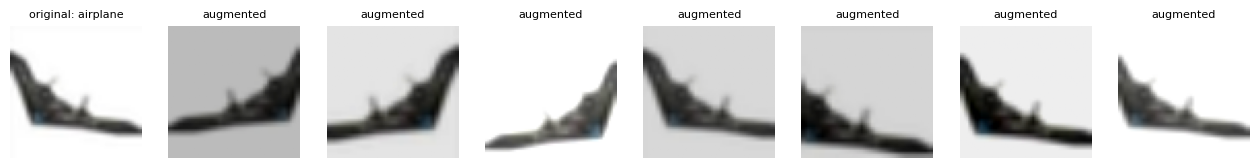

In [8]:
def denorm(x):
    m = torch.tensor(IMNET_MEAN).view(3, 1, 1); s = torch.tensor(IMNET_STD).view(3, 1, 1)
    return (x * s + m).clamp(0, 1)

raw = torchvision.datasets.CIFAR10(root, train=True, download=False)   # PIL images
img, label = raw[train_idx[3]]

fig, axes = plt.subplots(1, 8, figsize=(16, 2.4))
axes[0].imshow(img.resize((IMG, IMG))); axes[0].set_title("original: " + CLASSES[label], fontsize=8)
for ax in axes[1:]:
    ax.imshow(denorm(aug_tf(img)).permute(1, 2, 0)); ax.set_title("augmented", fontsize=8)
for ax in axes:
    ax.axis("off")
plt.show()

**THINK (Part 3):** We use horizontal flips but deliberately no vertical flips and no large rotations. For roadside scene recognition, why would those be unrealistic or harmful? Which augmentation would you add for night-time cameras?

*My answer:* A roadside camera is mounted upright, so vertical flips and large rotations would create scenes that never happen (sky below the road, upside-down trucks, animals walking on the ceiling). They would waste training effort on impossible images and could break useful context cues such as "road at the bottom, sky at the top". For night-time cameras I would add stronger brightness/contrast jitter (much darker images), plus noise and blur to imitate low light and sensor noise.

In [9]:
ft_model = copy.deepcopy(fe_model)             # start from the trained head (workflow step 3)
for p in ft_model.layer4.parameters():
    p.requires_grad = True                     # unfreeze the last block
ft_model.fc[0].p = 0.3                         # dropout of 30% in front of the classifier

opt = torch.optim.AdamW([
    {"params": ft_model.layer4.parameters(), "lr": 1e-4},   # pretrained: gentle
    {"params": ft_model.fc.parameters(),     "lr": 1e-3},   # new head: faster
], weight_decay=1e-2)

total = sum(p.numel() for p in ft_model.parameters())
print(f"Trainable parameters: {trainable(ft_model):,} of {total:,} ({trainable(ft_model) / total:.0%})")

Trainable parameters: 8,398,858 of 11,181,642 (75%)


In [10]:
hist_ft = fit(ft_model, opt, train_aug, val_loader, EP_FT, "fine-tune")

[fine-tune] epoch 1/6 | train 64.8% (loss 1.011) | val 75.6% (loss 0.751) | 7s


[fine-tune] epoch 2/6 | train 76.7% (loss 0.674) | val 76.5% (loss 0.694) | 7s


[fine-tune] epoch 3/6 | train 81.5% (loss 0.519) | val 77.9% (loss 0.679) | 7s


[fine-tune] epoch 4/6 | train 85.3% (loss 0.413) | val 77.2% (loss 0.681) | 7s


[fine-tune] epoch 5/6 | train 88.2% (loss 0.345) | val 78.8% (loss 0.695) | 7s


[fine-tune] epoch 6/6 | train 89.7% (loss 0.301) | val 78.1% (loss 0.736) | 7s


## Part 4: Compare, Diagnose and Evaluate

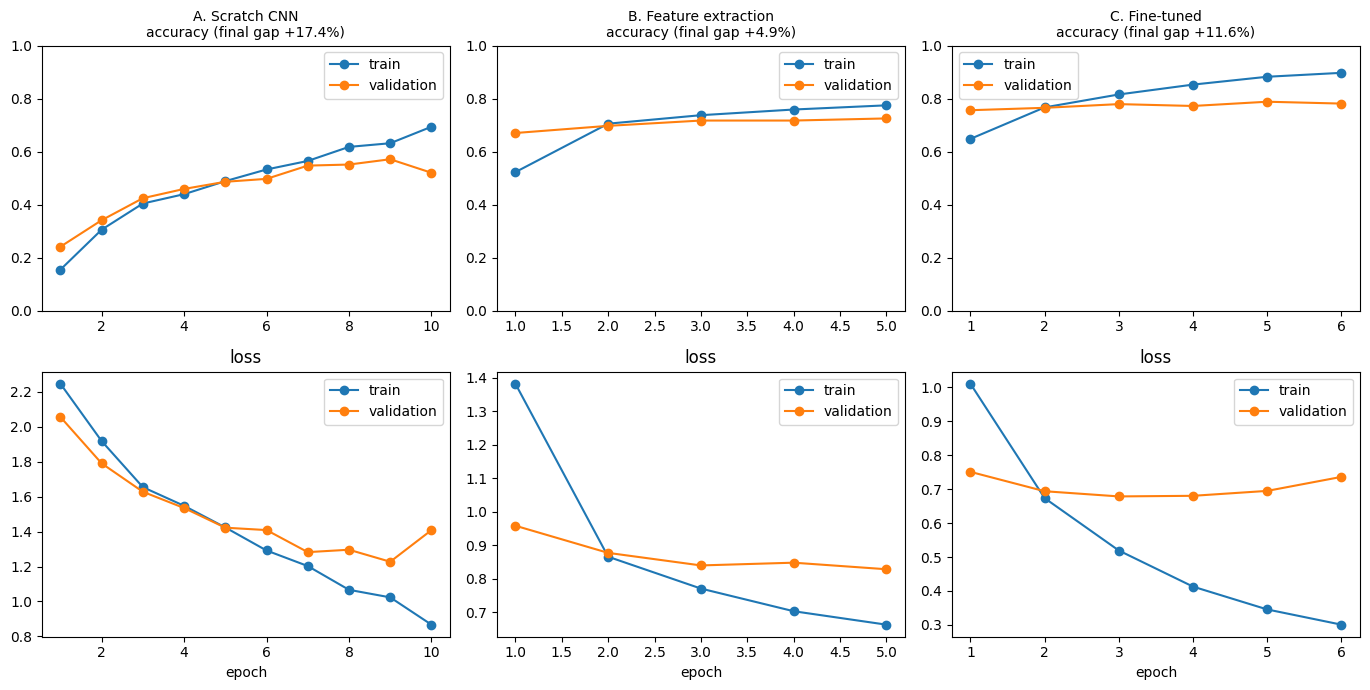

In [11]:
def plot_curves(hists):
    fig, axes = plt.subplots(2, len(hists), figsize=(4.6 * len(hists), 7), squeeze=False)
    for j, (name, h) in enumerate(hists.items()):
        e = range(1, len(h["val_acc"]) + 1)
        gap = h["train_acc"][-1] - h["val_acc"][-1]
        axes[0, j].plot(e, h["train_acc"], "o-", label="train")
        axes[0, j].plot(e, h["val_acc"], "o-", label="validation")
        axes[0, j].set_ylim(0, 1); axes[0, j].legend()
        axes[0, j].set_title(f"{name}\naccuracy (final gap {gap:+.1%})", fontsize=10)
        axes[1, j].plot(e, h["train_loss"], "o-", label="train")
        axes[1, j].plot(e, h["val_loss"], "o-", label="validation")
        axes[1, j].set_xlabel("epoch"); axes[1, j].set_title("loss"); axes[1, j].legend()
    plt.tight_layout(); plt.show()

plot_curves({"A. Scratch CNN": hist_scratch,
             "B. Feature extraction": hist_fe,
             "C. Fine-tuned": hist_ft})

In [12]:
rows = [("A. Scratch CNN",          scratch,  w3_test_loader, hist_scratch),
        ("B. Feature extraction",   fe_model, test_loader,    hist_fe),
        ("C. Fine-tuned ResNet-18", ft_model, test_loader,    hist_ft)]

print(f"{'Model':<26}{'trainable params':>18}{'val acc':>10}{'test acc':>10}")
test_acc = {}
for name, m, loader, h in rows:
    _, acc = run_epoch(m, loader)
    test_acc[name] = acc
    print(f"{name:<26}{trainable(m):>18,}{h['val_acc'][-1]:>10.1%}{acc:>10.1%}")

Model                       trainable params   val acc  test acc


A. Scratch CNN                       620,362     52.0%     50.4%


B. Feature extraction                  5,130     72.5%     71.8%


C. Fine-tuned ResNet-18            8,398,858     78.1%     77.8%


In [13]:
probs, ys = predict_all(ft_model, test_loader)
preds = probs.argmax(1)
cm = confusion(ys, preds)

prec = cm.diagonal() / np.maximum(cm.sum(0), 1)
rec  = cm.diagonal() / np.maximum(cm.sum(1), 1)
f1   = 2 * prec * rec / np.maximum(prec + rec, 1e-9)

probs_s, ys_s = predict_all(scratch, w3_test_loader)
rec_s = confusion(ys_s, probs_s.argmax(1)).diagonal() / 1000

print(f"{'class':<11}{'precision':>10}{'recall':>8}{'F1':>7}{'recall (scratch)':>18}{'gain':>8}")
for i, c in enumerate(CLASSES):
    print(f"{c:<11}{prec[i]:>10.1%}{rec[i]:>8.1%}{f1[i]:>7.2f}{rec_s[i]:>18.1%}{rec[i] - rec_s[i]:>+8.1%}")
print(f"\nmacro-F1 (fine-tuned): {f1.mean():.3f}")

off = cm.copy(); np.fill_diagonal(off, 0)
print("\nThree most common mistakes of the fine-tuned model:")
for idx in np.argsort(-off.ravel())[:3]:
    t, p_ = divmod(idx, 10)
    print(f"  {CLASSES[t]} predicted as {CLASSES[p_]}: {off[t, p_]} times")

class       precision  recall     F1  recall (scratch)    gain
airplane        72.9%   87.8%   0.80             75.3%  +12.5%
automobile      85.2%   87.4%   0.86             55.3%  +32.1%
bird            71.3%   69.3%   0.70             67.0%   +2.3%
cat             68.0%   56.8%   0.62             49.0%   +7.8%
deer            74.9%   70.1%   0.72             20.6%  +49.5%
dog             69.7%   73.9%   0.72             24.7%  +49.2%
frog            72.3%   89.4%   0.80             42.7%  +46.7%
horse           87.0%   75.6%   0.81             36.6%  +39.0%
ship            90.2%   85.9%   0.88             71.3%  +14.6%
truck           90.6%   82.3%   0.86             61.4%  +20.9%

macro-F1 (fine-tuned): 0.777

Three most common mistakes of the fine-tuned model:
  cat predicted as dog: 179 times
  dog predicted as cat: 113 times
  truck predicted as automobile: 100 times


In [14]:
VEHICLES = torch.tensor([0, 1, 8, 9])            # airplane, automobile, ship, truck
true_v, pred_v = torch.isin(ys, VEHICLES), torch.isin(preds, VEHICLES)
print(f"10-class (object-level) accuracy : {(preds == ys).float().mean():.2%}")
print(f"Vehicle vs animal (scene-level)  : {(true_v == pred_v).float().mean():.2%}")

animal_as_vehicle = ((~true_v) & pred_v).sum().item() / (~true_v).sum().item()
print(f"Animals mistaken for vehicles    : {animal_as_vehicle:.1%}   <- the costly error for a deer warning")

10-class (object-level) accuracy : 77.85%
Vehicle vs animal (scene-level)  : 96.11%
Animals mistaken for vehicles    : 4.0%   <- the costly error for a deer warning


**THINK (Part 4):** Compare the recall column of the fine-tuned model with the scratch model. Which classes gained the most? Using Week 3's idea of edges → textures → parts → objects, why might pretrained features help most for those classes? And why is overall accuracy alone not enough to decide whether the system is safe to deploy?

*My answer:* The largest recall gains were for deer (+49.5%, from 20.6% to 70.1%), dog (+49.2%), frog (+46.7%) and horse (+39.0%), mostly animal classes. These classes are told apart by textures and parts (fur, legs, heads) rather than simple shapes, and the scratch CNN trained on 5,000 images could not learn rich part detectors, while the pretrained backbone already has them from the edges → textures → parts → objects hierarchy it learned on ImageNet. Overall accuracy (77.85%) is not enough for deployment because it hides weak classes (cat recall only 56.8%) and the costly errors: 4.0% of animals were still mistaken for vehicles, which for a deer warning means missed warnings.

## Part 5: Pitfall Demo, Wrong Input Normalisation

In [15]:
def val_acc_with(transform):
    ds = torchvision.datasets.CIFAR10(root, train=True, download=False, transform=transform)
    loader = DataLoader(Subset(ds, val_idx), batch_size=128, shuffle=False, num_workers=0)
    return run_epoch(ft_model, loader)[1]

variants = {
    "ImageNet stats (correct)":   T.Compose([T.Resize(IMG), T.ToTensor(), T.Normalize(IMNET_MEAN, IMNET_STD)]),
    "CIFAR stats (close, wrong)": T.Compose([T.Resize(IMG), T.ToTensor(), T.Normalize(CIFAR_MEAN, CIFAR_STD)]),
    "No normalisation (0..1)":    T.Compose([T.Resize(IMG), T.ToTensor()]),
}
for name, tf_ in variants.items():
    print(f"{name:<30} validation accuracy = {val_acc_with(tf_):.1%}")

ImageNet stats (correct)       validation accuracy = 78.1%


CIFAR stats (close, wrong)     validation accuracy = 78.0%


No normalisation (0..1)        validation accuracy = 48.1%


## Reflection

**1. Transfer vs scratch:** With only 5,000 labelled images, the scratch CNN reached 50.4% test accuracy, while feature extraction reached 71.8% and fine-tuning 77.8% (Cell 4.2). The pretrained models start with general features learned from 1.28 million ImageNet images, so only a few parameters (5,130 for B) have to be learned from our small dataset, whereas the scratch model must learn everything from 5,000 images and starts memorising them. I would choose feature extraction (B) when I have very little data, when the images are similar to ImageNet, or when compute is tight (it trains fastest, about 3 s per epoch here, and has 1,600× fewer trainable parameters than C).

**2. Curves and regularisation:** The final train/validation gap was +17.4 points for model A (69.4% vs 52.0%, with validation loss rising from 1.227 to 1.409 in the last epoch) and +11.6 points for model C (89.7% vs 78.1%), even though C has many more trainable parameters. I think augmentation contributed most (each epoch shows different variations, so memorising is harder), helped by dropout and weight decay in the head and the small 1e-4 learning rate that protects the pretrained features. From a single run these effects cannot be separated, because C changes several things at once; I would test them with ablations that change one factor at a time (e.g. fine-tuning with `train_plain` instead of `train_aug`, or dropout 0), repeated over several seeds.

**3. Honest evaluation:** I used the validation set (100 images per class, disjoint from training, checked by the assert) for every decision, including choosing the fine-tuned model, and the official CIFAR-10 test set only once, in Cell 4.2, to report the final numbers. Leakage could have crept in if the train and validation indices had overlapped, if normalisation statistics had been computed on all data including test, or if I had retuned after seeing the test results. I would trust the system least on **cat**: it has the lowest recall (56.8%) and F1 (0.62), and cat → dog is the most common mistake (179 times).